# 1. Data Understanding and Preparation
**Dataset:** Seller-Level Vehicle Listings Dataset (`seller_info_dm1_2627.csv`)  
Each record corresponds to a single seller/dealer (`sp_id`) and summarizes the vehicle listings observed for that seller (13,843 rows × 33 columns).

Structure of this notebook (aligned with Project Guidelines & Sample Reports):
* **1.1. Data Semantics**
  * 1.1.1. Load Dataset & General Overview
  * 1.1.2. Semantic Description Table (Variable Name, Description, Source Datatype, Measurement Scale Type)
  * 1.1.3. Initial Datatype & Semantic Inconsistencies Check
* **1.2. Distribution of Variables and Statistics**
  * 1.2.1. Summary of Statistics (Numerical & Categorical)
  * 1.2.2. Distribution of Numerical Variables (Histograms & Skewness)
  * 1.2.3. Distribution of Categorical Variables (Pie Charts, Bar Charts & Cross-tab Heatmaps)
* **1.3. Assessment of Data Quality**
  * 1.3.1. Missing Value Analysis & Tailored Imputation Strategies
  * 1.3.2. Outlier and Noise Detection (Boxplots, Semantic Checks & Filtering)
* **1.4. Variables Transformation**
  * 1.4.1. Log-Transformation for Highly Skewed Variables
  * 1.4.2. Feature Scaling (Z-Score Standardization / Min-Max Normalization)
* **1.5. Pairwise Correlations and Variable Elimination**
  * 1.5.1. Pairwise Scatter Plot Matrix
  * 1.5.2. Spearman Correlation Matrix Heatmap & Redundant Feature Elimination


## 1.1. Data Semantics
### 1.1.1. Load Dataset & General Overview
Load the dataset, inspect its dimensions, first few records, and initial pandas data types.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)

# Load dataset (supports running from workspace root, repo root, or project/ subfolder)
candidate_paths = [
    "dataset/seller_info_dm1_2627.csv",
    "project/dataset/seller_info_dm1_2627.csv",
    "dm1_26_27_dataset/seller_info_dm1_2627.csv",
    "../dm1_26_27_dataset/seller_info_dm1_2627.csv"
]
DATA_PATH = next(p for p in candidate_paths if os.path.exists(p))

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded from: {DATA_PATH}")
print(f"Dataset Shape: {df.shape[0]:,} rows (sellers) x {df.shape[1]} columns (features)")
display(df.head())


Dataset Shape: 13,843 rows (sellers) x 33 columns (features)


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.0,68.9,195.35,77.10,0.133333,0.0,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.9,64.7,180.30,72.50,0.058824,0.0,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.5,58.1,188.20,72.00,0.111111,0.0,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.5,57.9,190.05,72.05,0.000000,0.0,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.1,70.2,187.60,74.00,0.000000,0.0,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


### 1.1.2. Semantic Description Table
Build a comprehensive table summarizing all 33 features, including:
1. **Variable Name**
2. **Description** (from dataset documentation)
3. **Source Datatype** (`int64`, `float64`, `object`)
4. **Measurement Scale Type** (`Identifier`, `Numerical (Discrete)`, `Numerical (Continuous)`, `Categorical (Nominal)`, `Categorical (Ordinal)`)


In [2]:
# Define semantic metadata for all 33 attributes
semantics_info = [
    ("sp_id", "Unique identifier of the seller/dealer", "Identifier (Nominal)"),
    ("n_listings", "Total number of vehicle listings associated with the seller", "Numerical (Discrete / Ratio)"),
    ("price_median", "Median advertised price of the vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("savings_amount_median", "Median advertised savings amount of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("daysonmarket_median", "Median number of days vehicles remained listed on the market", "Numerical (Continuous / Ratio)"),
    ("mileage_median", "Median mileage of the vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("year_median", "Median model year of the vehicles listed by the seller", "Numerical (Continuous / Interval)"),
    ("vehicle_age_median", "Median age of vehicles at listing time (listing year - model year)", "Numerical (Continuous / Ratio)"),
    ("owner_count_median", "Median number of previous owners of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("horsepower_median", "Median horsepower of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("engine_displacement_median", "Median engine displacement (cc) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("city_fuel_economy_median", "Median city fuel economy (MPG) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("highway_fuel_economy_median", "Median highway fuel economy (MPG) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("back_legroom_median", "Median rear-seat legroom (inches) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("front_legroom_median", "Median front-seat legroom (inches) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("fuel_tank_volume_median", "Median fuel-tank capacity (gallons) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("height_median", "Median vehicle height (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("length_median", "Median vehicle length (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("width_median", "Median vehicle width (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("pct_isCab", "Proportion of listed vehicles previously used as taxis/cabs", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_is_new", "Proportion of listed vehicles classified as new vehicles", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_salvage", "Proportion of listed vehicles having salvage status", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_theft_title", "Proportion of listed vehicles having a theft-related title", "Numerical (Continuous / Ratio [0,1])"),
    ("n_listing_days", "Number of distinct calendar days on which listings are observed", "Numerical (Discrete / Ratio)"),
    ("listing_span_days", "Number of days between earliest and latest listing observed", "Numerical (Discrete / Ratio)"),
    ("dominant_body_type", "Most frequently represented vehicle body type in seller's inventory", "Categorical (Nominal)"),
    ("dominant_fuel_type", "Most frequently represented fuel type among seller's vehicles", "Categorical (Nominal)"),
    ("dominant_transmission", "Most frequently represented transmission type (a, cvt, m, unknown)", "Categorical (Nominal)"),
    ("dominant_wheel_system", "Most frequently represented drivetrain/wheel-system configuration", "Categorical (Nominal)"),
    ("dominant_listing_color", "Most frequently represented standardized exterior color", "Categorical (Nominal)"),
    ("franchise_status", "Seller category based on franchise listings (franchise, independent)", "Categorical (Nominal / Binary)"),
    ("new_used_profile", "Inventory composition w.r.t. new/used vehicles (used_only, mixed, new_only)", "Categorical (Nominal)"),
    ("seller_rating_class", "Target variable: Discretized seller rating category (low, medium, high)", "Categorical (Ordinal - Target)")
]

semantics_df = pd.DataFrame(semantics_info, columns=["Variable Name", "Description", "Measurement Scale Type"])
semantics_df["Source Datatype"] = semantics_df["Variable Name"].map(df.dtypes.astype(str))
semantics_df["Missing (NaN) Count"] = semantics_df["Variable Name"].map(df.isnull().sum())
semantics_df["Missing (%)"] = (semantics_df["Missing (NaN) Count"] / len(df) * 100).round(2)

# Reorder columns to match report table format
semantics_df = semantics_df[[
    "Variable Name", "Description", "Source Datatype", "Measurement Scale Type", "Missing (NaN) Count", "Missing (%)"
]]
display(semantics_df)


,Variable Name,Description,Source Datatype,Measurement Scale Type,Missing (NaN) Count,Missing (%)
0,sp_id,Unique identifier of the seller/dealer,float64,Identifier (Nominal),0,0.00
1,n_listings,Total number of vehicle listings associated wi...,int64,Numerical (Discrete / Ratio),0,0.00
2,price_median,Median advertised price of the vehicles listed...,float64,Numerical (Continuous / Ratio),0,0.00
3,savings_amount_median,Median advertised savings amount of vehicles l...,float64,Numerical (Continuous / Ratio),0,0.00
4,daysonmarket_median,Median number of days vehicles remained listed...,float64,Numerical (Continuous / Ratio),0,0.00
5,mileage_median,Median mileage of the vehicles listed by the s...,float64,Numerical (Continuous / Ratio),1,0.01
6,year_median,Median model year of the vehicles listed by th...,float64,Numerical (Continuous / Interval),0,0.00
7,vehicle_age_median,Median age of vehicles at listing time (listin...,float64,Numerical (Continuous / Ratio),1,0.01
8,owner_count_median,Median number of previous owners of vehicles l...,float64,Numerical (Continuous / Ratio),39,0.28
9,horsepower_median,Median horsepower of vehicles listed by the se...,float64,Numerical (Continuous / Ratio),6,0.04


### 1.1.3. Initial Datatype & Semantic Inconsistencies Check
Before exploring variable distributions, we perform a systematic audit of **datatype mismatches** and **domain semantic inconsistencies** across all 33 features:

1. **Datatype vs. Measurement Scale Check:**
   * `sp_id` is stored as `float64` (e.g., `404771.0`), whereas semantically it is a unique nominal **Identifier** (`0` duplicates across $13,843$ rows). It must be converted to string/integer ID so it is excluded from numerical statistics.
   * `seller_rating_class` (`low`, `medium`, `high`) and `new_used_profile` (`used_only`, `mixed`, `new_only`) are stored as generic `object` strings, but possess a natural **Ordinal** hierarchy.
   * Count/year variables (`year_median`, `owner_count_median`, `daysonmarket_median`) are stored as `float64` with `.5` decimal values (e.g., `2010.5`, `1.5`). Verification confirms this is **mathematically valid** because each record is an aggregation at the seller level: when a seller has an even number of listings, the median of two integers yields a `.5` value.
2. **Implicit / Non-Standard Missing Values (`"unknown"` strings):**
   * Although the dataset documentation mentions `"unknown"` for `franchise_status` and `new_used_profile`, neither contains `"unknown"` ($0\%$).
   * Instead, three other categorical attributes encode missing data as `"unknown"` strings rather than `NaN`: `dominant_listing_color` ($1,510$ rows, $10.91\%$), `dominant_transmission` ($6$ rows, $0.04\%$), and `dominant_fuel_type` ($1$ row, $0.01\%$).
3. **Cross-Feature Semantic Consistency & Redundancy:**
   * **`new_used_profile` vs. `pct_is_new`:** `used_only` ($7,384$ rows) has $\text{pct\_is\_new} = 0.0$ ($100\%$); `mixed` ($6,428$ rows) has $0 < \text{pct\_is\_new} < 1$ ($100\%$); `new_only` ($31$ rows) has $\text{pct\_is\_new} = 1.0$ ($100\%$). Thus, `new_used_profile` is a deterministic discretization of `pct_is_new` with zero semantic contradictions.
   * **Temporal & Activity Constraints:** Every seller satisfies `n_listing_days <= n_listings` ($0$ violations) and `n_listing_days <= listing_span_days + 1` ($0$ violations).
   * **Category Label Overlap in `dominant_wheel_system`:** Contains `"4x2"` ($23$ rows) alongside `"fwd"` ($1,781$) and `"rwd"` ($129$). In automotive terminology, `"4x2"` (2-wheel drive on a 4-wheel vehicle) is semantically redundant with `"fwd"`/`"rwd"`.
4. **Physical & Domain Value Anomalies (`<= 0` check):**
   * Zero values in `savings_amount_median`, `daysonmarket_median`, `mileage_median`, `vehicle_age_median`, and `pct_*` are valid (e.g., brand-new vehicles with $0$ age/mileage or $0$ discount).
   * However, **`back_legroom_median == 0.0` inches** occurs in $3$ sellers whose dominant body types are `suv_crossover` and `sedan` (which physically have rear seats). These $3$ zeros represent disguised missing/erroneous entries and are converted to `NaN` for imputation.


In [3]:
# ==============================================================================
# 1. DATATYPE VS. MEASUREMENT SCALE CHECK (sp_id & .5 median verification)
# ==============================================================================
print("=== [1] DATATYPE & AGGREGATION (.5 MEDIAN) CHECK ===")
print(f"sp_id original dtype: {df_raw['sp_id'].dtype} | Example: {df_raw['sp_id'].iloc[0]} | Duplicates: {df_raw['sp_id'].duplicated().sum()}")

# Convert sp_id to string identifier
df["sp_id"] = df_raw["sp_id"].astype(int).astype(str)

# Verify why integer-like attributes (year_median, owner_count_median, daysonmarket_median) have .5 decimals
half_year_mask = (df["year_median"] % 1 != 0)
print(f"Sellers with .5 in year_median: {half_year_mask.sum():,} ({half_year_mask.mean()*100:.2f}%)")
print("Sample sellers with .5 in year_median or owner_count_median (caused by even number of listings):")
display(df.loc[half_year_mask, ["sp_id", "n_listings", "year_median", "vehicle_age_median", "owner_count_median"]].head(5))


# ==============================================================================
# 2. IMPLICIT MISSING VALUES ("unknown" STRINGS IN CATEGORICAL COLUMNS)
# ==============================================================================
print("\n=== [2] IMPLICIT MISSING VALUES ('unknown' STRINGS) IN CATEGORICAL COLUMNS ===")
cat_cols = df.select_dtypes(include=["object"]).columns.drop("sp_id").tolist()
cat_audit_rows = []
for col in cat_cols:
    nan_cnt = df[col].isnull().sum()
    unk_cnt = (df[col] == "unknown").sum()
    top_vals = ", ".join([f"{k}: {v}" for k, v in df[col].fillna("NaN").value_counts().head(5).items()])
    cat_audit_rows.append({
        "Categorical Variable": col,
        "Unique (incl. NaN)": df[col].nunique(dropna=False),
        "Explicit NaN": nan_cnt,
        "Implicit 'unknown'": unk_cnt,
        "Total Missing (%)": round((nan_cnt + unk_cnt) / len(df) * 100, 2),
        "Top Categories (Counts)": top_vals
    })
display(pd.DataFrame(cat_audit_rows))


# ==============================================================================
# 3. CROSS-FEATURE SEMANTIC CONSISTENCY CHECKS
# ==============================================================================
print("\n=== [3A] SEMANTIC CONSISTENCY: new_used_profile vs. pct_is_new ===")
profile_check = df.groupby("new_used_profile")["pct_is_new"].agg(
    count="count",
    min="min",
    median="median",
    max="max",
    exact_zero_count=lambda s: (s == 0.0).sum(),
    exact_one_count=lambda s: (s == 1.0).sum()
)
display(profile_check)

print("=== [3B] TEMPORAL & ACTIVITY LOGIC CONSTRAINTS ===")
v_days_listings = (df["n_listing_days"] > df["n_listings"]).sum()
v_days_span = (df["n_listing_days"] > df["listing_span_days"] + 1).sum()
v_span_zero = ((df["listing_span_days"] == 0) & (df["n_listing_days"] > 1)).sum()
print(f"Violations of (n_listing_days <= n_listings)          : {v_days_listings}")
print(f"Violations of (n_listing_days <= listing_span_days+1) : {v_days_span}")
print(f"Violations of (listing_span_days==0 & n_listing_days>1): {v_span_zero}")


# ==============================================================================
# 4. PHYSICAL / DOMAIN VALUE ANOMALIES (ZERO OR NEGATIVE VALUES CHECK)
# ==============================================================================
print("\n=== [4] PHYSICAL & DOMAIN ZERO/NEGATIVE VALUE CHECK ===")
num_cols_check = df.select_dtypes(include=[np.number]).columns.tolist()
zero_neg_summary = []
for col in num_cols_check:
    neg_cnt = (df[col] < 0).sum()
    zero_cnt = (df[col] == 0).sum()
    if neg_cnt > 0 or zero_cnt > 0:
        zero_neg_summary.append({
            "Numerical Variable": col,
            "Negative (< 0)": neg_cnt,
            "Zero (== 0)": zero_cnt,
            "Zero (%)": round(zero_cnt / len(df) * 100, 2),
            "Domain Interpretation": (
                "ERROR / Disguised Missing (SUV/Sedan cannot have 0 rear legroom)"
                if col == "back_legroom_median"
                else "Valid domain zero (new cars, no discount, or 0% proportion)"
            )
        })
display(pd.DataFrame(zero_neg_summary))

print("Inspecting the 3 anomalous records with back_legroom_median == 0.0:")
display(df.loc[df["back_legroom_median"] == 0, [
    "sp_id", "n_listings", "dominant_body_type", "back_legroom_median", "front_legroom_median", "length_median", "width_median"
]])

# Replace the 3 erroneous 0.0 values in back_legroom_median with NaN so they are properly imputed in Section 1.3.1
df.loc[df["back_legroom_median"] == 0, "back_legroom_median"] = np.nan
print(f"-> Converted 3 erroneous zeros in back_legroom_median to NaN (new NaN count: {df['back_legroom_median'].isnull().sum()}).")


=== CATEGORICAL COLUMNS & 'unknown' VALUES ===

-> dominant_body_type (unique=9, 'unknown'=0 [0.00%]):
{'suv_crossover': 8920, 'sedan': 3044, 'pickup_truck': 1424, 'coupe': 167, 'hatchback': 97, 'van': 82, 'convertible': 63, 'minivan': 39, 'wagon': 7}

-> dominant_fuel_type (unique=7, 'unknown'=1 [0.01%]):
{'gasoline': 13658, 'flex_fuel_vehicle': 91, 'diesel': 52, 'biodiesel': 16, 'hybrid': 13, 'electric': 12, 'unknown': 1}

-> dominant_transmission (unique=4, 'unknown'=6 [0.04%]):
{'a': 12976, 'cvt': 847, 'm': 14, 'unknown': 6}

-> dominant_wheel_system (unique=6, 'unknown'=0 [0.00%]):
{nan: 10518, 'fwd': 1781, 'awd': 724, '4wd': 668, 'rwd': 129, '4x2': 23}

-> dominant_listing_color (unique=11, 'unknown'=1510 [10.91%]):
{'white': 5167, 'black': 4475, 'unknown': 1510, 'silver': 992, 'gray': 875, 'red': 417, 'blue': 372, 'brown': 17, 'green': 12, 'gold': 5, 'teal': 1}

-> franchise_status (unique=2, 'unknown'=0 [0.00%]):
{'franchise': 6999, 'independent': 6844}

-> new_used_profile (un

,count,mean,std,min,25%,50%,75%,max
new_used_profile,,,,,,,,
mixed,6428.0,0.571319,0.197562,0.001715,0.462963,0.604426,0.715418,0.981818
new_only,31.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
used_only,7384.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


---
## 1.2. Distribution of Variables and Statistics
### 1.2.1. Summary of Statistics
Compute primary descriptive statistics (`Count`, `Mean`, `Std`, `Min`, `25%`, `50%`, `75%`, `Max`, `Skewness`, `Kurtosis`) for all numerical features.


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

stats_df = df[num_cols].describe().T
stats_df["skew"] = df[num_cols].skew()
stats_df["kurtosis"] = df[num_cols].kurtosis()
stats_df["iqr"] = stats_df["75%"] - stats_df["25%"]

display(stats_df.round(2))


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,iqr
n_listings,13843.0,118.10,137.06,5.00,25.00,70.00,168.00,4959.00,5.25,120.32,143.00
price_median,13843.0,23106.14,14365.07,1699.00,12495.00,22385.00,29888.00,236438.00,3.45,34.14,17393.00
savings_amount_median,13843.0,446.21,519.46,0.00,0.00,358.00,734.00,9333.00,2.40,18.30,734.00
daysonmarket_median,13843.0,49.15,56.06,0.00,26.00,36.00,51.00,1987.00,8.75,168.60,25.00
mileage_median,13842.0,51463.27,51845.46,0.00,25.00,33596.50,96915.75,238541.00,0.68,-0.77,96890.75
year_median,13843.0,2015.95,4.72,1960.00,2013.00,2017.00,2020.00,2021.00,-2.25,14.09,7.00
vehicle_age_median,13842.0,4.08,4.63,0.00,0.00,3.00,7.00,60.00,2.32,14.98,7.00
owner_count_median,13804.0,1.43,0.62,1.00,1.00,1.00,2.00,6.00,1.30,1.35,1.00
horsepower_median,13837.0,240.90,56.99,78.00,188.00,243.00,283.00,630.00,0.85,2.05,95.00
engine_displacement_median,10450.0,2925.08,808.08,1200.00,2400.00,2500.00,3500.00,6800.00,1.29,2.77,1100.00


### 1.2.2. Distribution of Numerical Variables (Histograms)
Plot histograms for all numerical features to inspect skewness, multi-modality, and long tails (potential outliers).


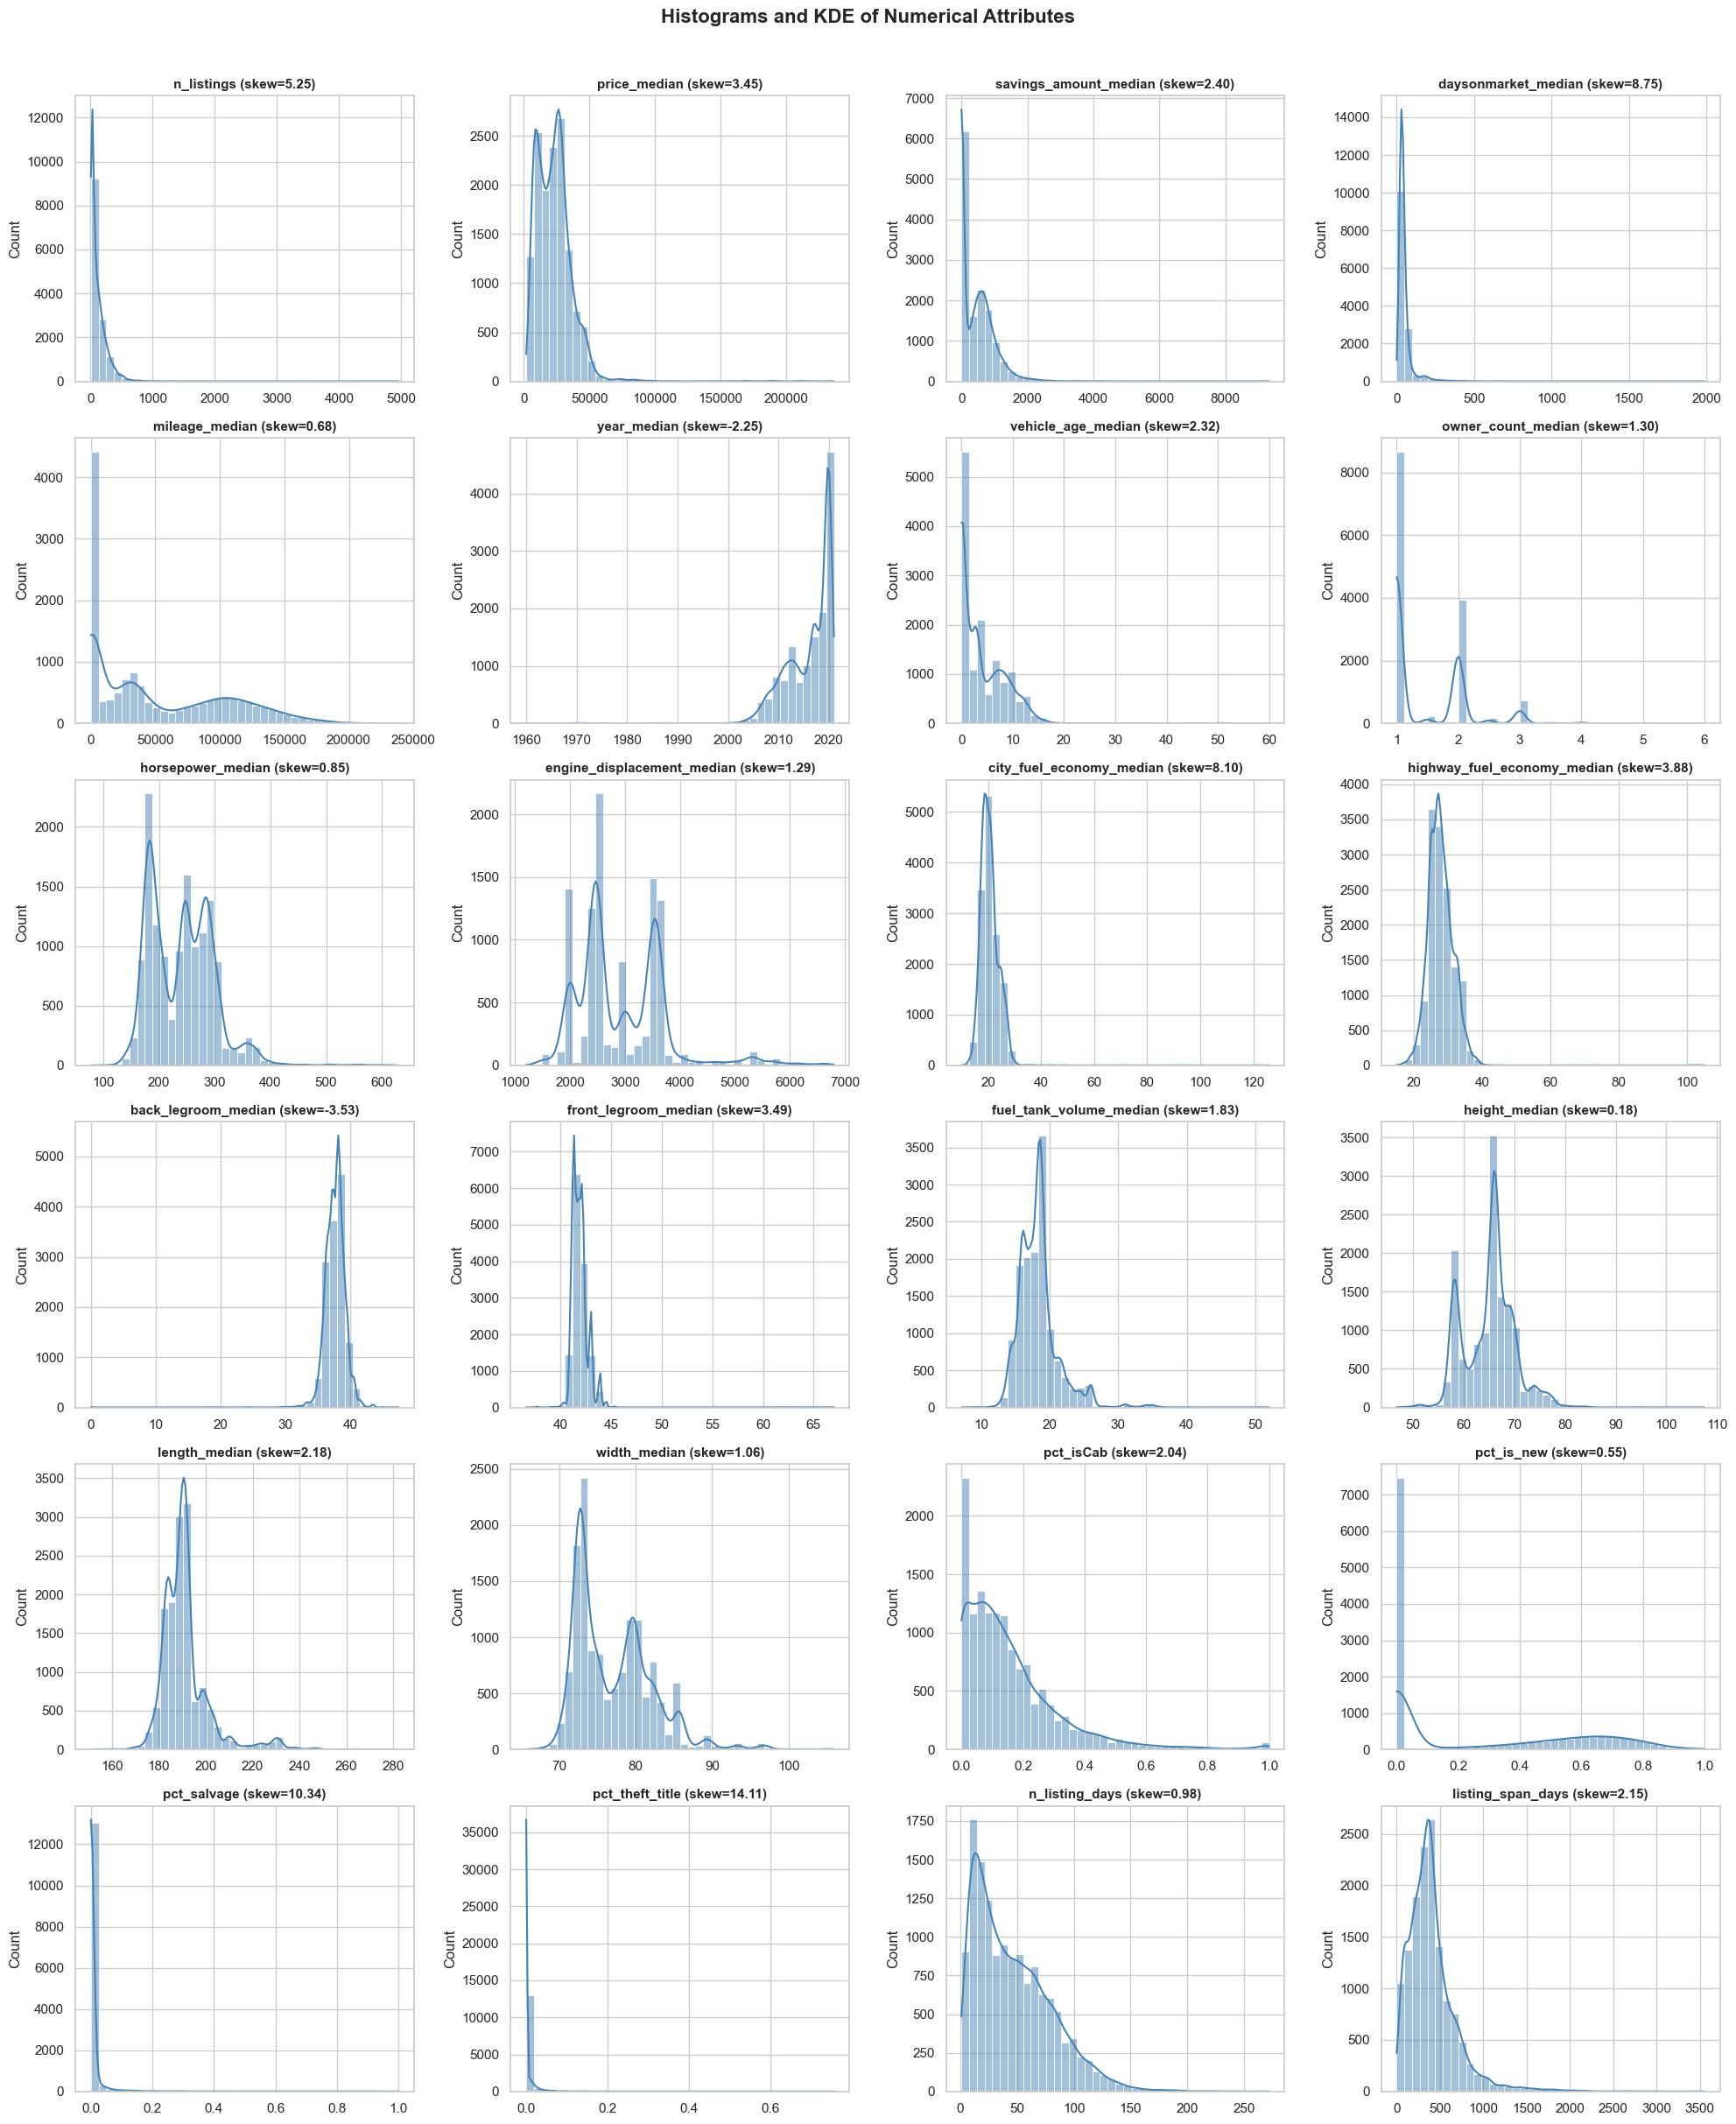

In [5]:
fig, axes = plt.subplots(6, 4, figsize=(20, 24))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=40, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col} (skew={df[col].skew():.2f})", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")

# Hide unused subplots
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle("Histograms and KDE of Numerical Attributes", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


### 1.2.3. Distribution of Categorical Variables (Pie Charts & Bar Charts)
Visualize the proportions of categorical variables and the target class `seller_rating_class`.


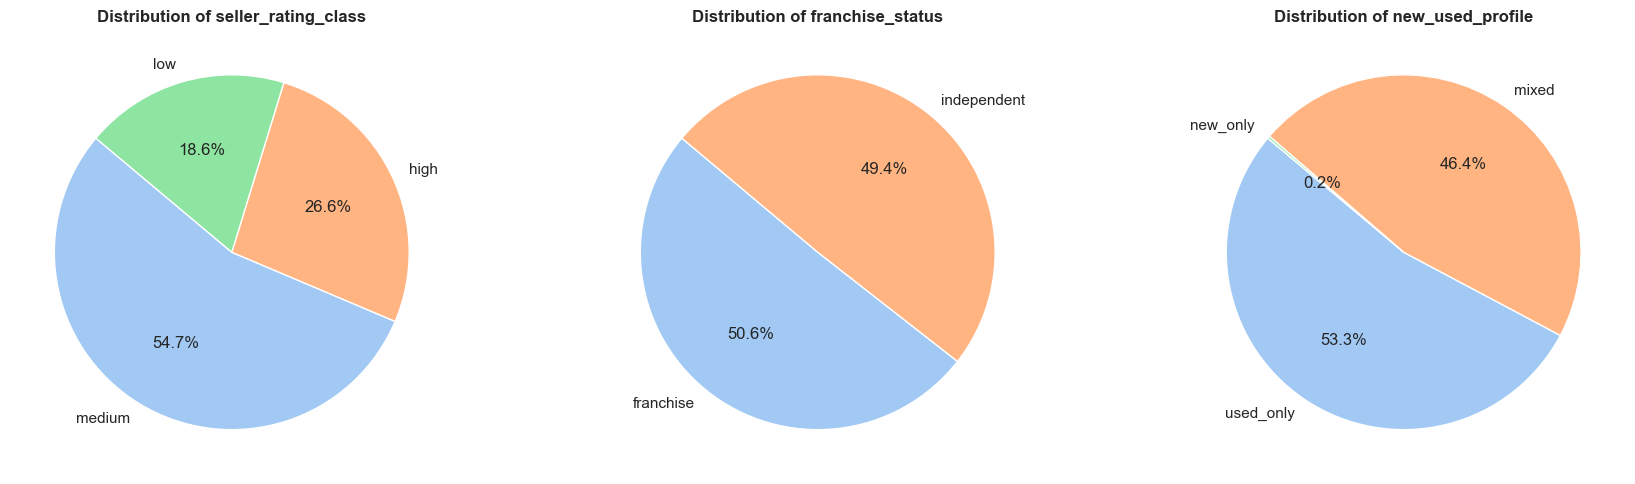

/var/folders/k3/yfnh9s6x14s36q_m9trj03pm0000gn/T/ipykernel_3125/791827082.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.fillna({"dominant_wheel_system": "Missing (NaN)"}), y=col, order=order, ax=axes[i], palette="viridis")
/var/folders/k3/yfnh9s6x14s36q_m9trj03pm0000gn/T/ipykernel_3125/791827082.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.fillna({"dominant_wheel_system": "Missing (NaN)"}), y=col, order=order, ax=axes[i], palette="viridis")
/var/folders/k3/yfnh9s6x14s36q_m9trj03pm0000gn/T/ipykernel_3125/791827082.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue`

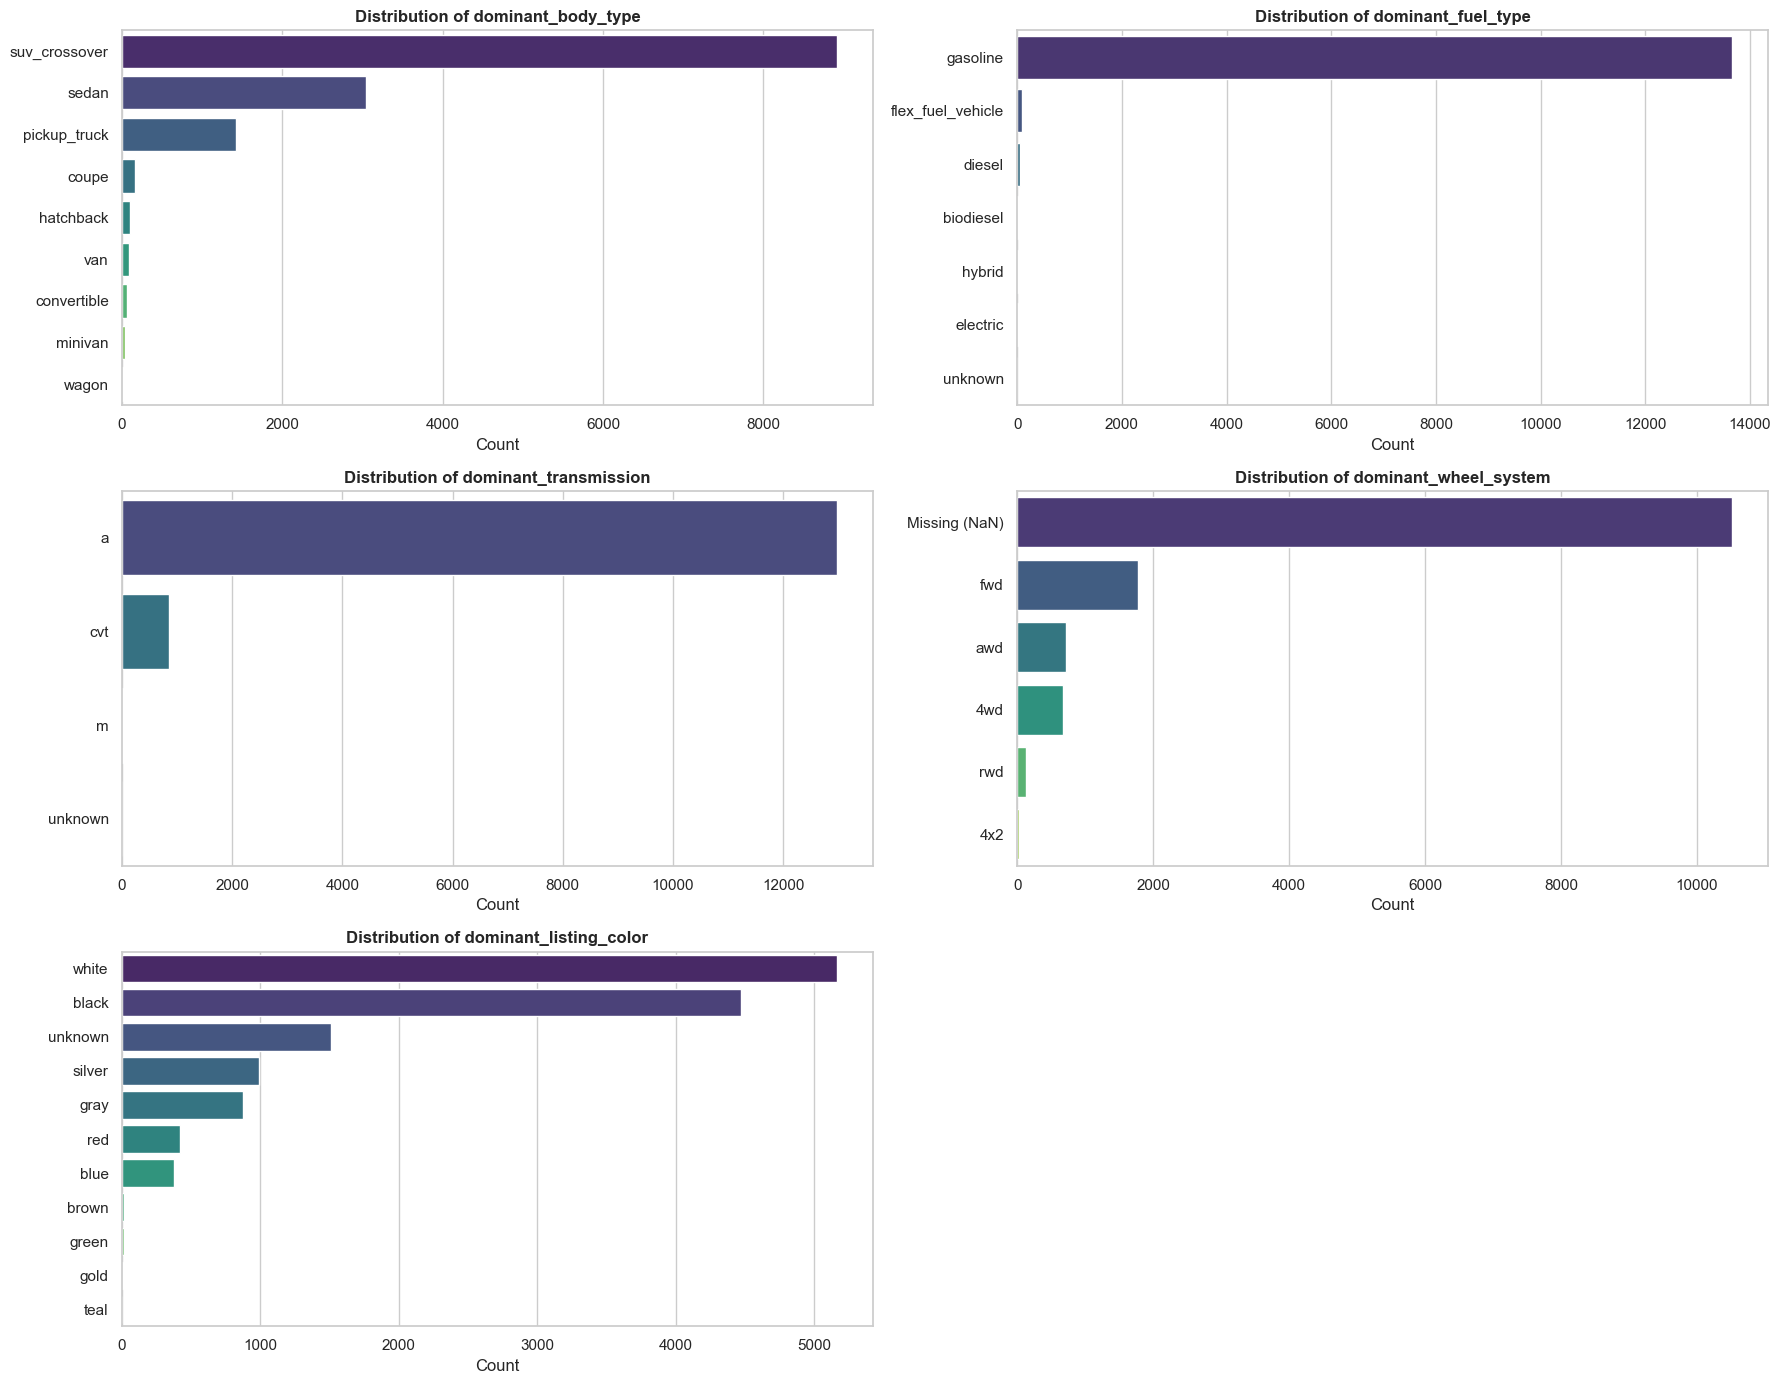

In [6]:
# Pie charts for low-cardinality categorical variables (franchise_status, new_used_profile, seller_rating_class)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

low_card_cols = ["seller_rating_class", "franchise_status", "new_used_profile"]
for i, col in enumerate(low_card_cols):
    counts = df[col].value_counts()
    axes[i].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("pastel"))
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

# Bar charts for remaining categorical variables
high_card_cols = ["dominant_body_type", "dominant_fuel_type", "dominant_transmission", "dominant_wheel_system", "dominant_listing_color"]
fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(high_card_cols):
    order = df[col].fillna("Missing (NaN)").value_counts().index
    sns.countplot(data=df.fillna({"dominant_wheel_system": "Missing (NaN)"}), y=col, order=order, ax=axes[i], palette="viridis")
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Count")
    axes[i].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


---
## 1.3. Assessment of Data Quality
### 1.3.1. Missing Value Handling
Analyze both explicit `NaN` values and implicit `"unknown"` values, then apply tailored imputation / removal strategies:
* **`dominant_wheel_system` (76.0% missing):** Drop column due to excessive missingness.
* **`engine_displacement_median` (24.5% missing):** Impute using the **median grouped by `dominant_body_type` and `dominant_fuel_type`** (since engine size strongly depends on vehicle body type and fuel type).
* **`vehicle_age_median` (1 missing):** Calculate mathematically from `year_median` (`2020 - year_median`).
* **Remaining numerical columns with < 0.3% missing (`owner_count_median`, `pct_isCab`, `pct_salvage`, `pct_theft_title`, dimensions, fuel economy, horsepower, mileage):** Impute with group median (e.g., by `dominant_body_type` or `new_used_profile`).


,Variable,NaN Count,NaN (%),'unknown' Count,'unknown' (%),Total Missing,Total Missing (%)
18,dominant_wheel_system,10518,75.98,0,0.00,10518,75.98
4,engine_displacement_median,3393,24.51,0,0.00,3393,24.51
19,dominant_listing_color,0,0.00,1510,10.91,1510,10.91
2,owner_count_median,39,0.28,0,0.00,39,0.28
13,pct_isCab,27,0.20,0,0.00,27,0.20
15,pct_theft_title,27,0.20,0,0.00,27,0.20
14,pct_salvage,27,0.20,0,0.00,27,0.20
7,back_legroom_median,19,0.14,0,0.00,19,0.14
5,city_fuel_economy_median,16,0.12,0,0.00,16,0.12
6,highway_fuel_economy_median,16,0.12,0,0.00,16,0.12


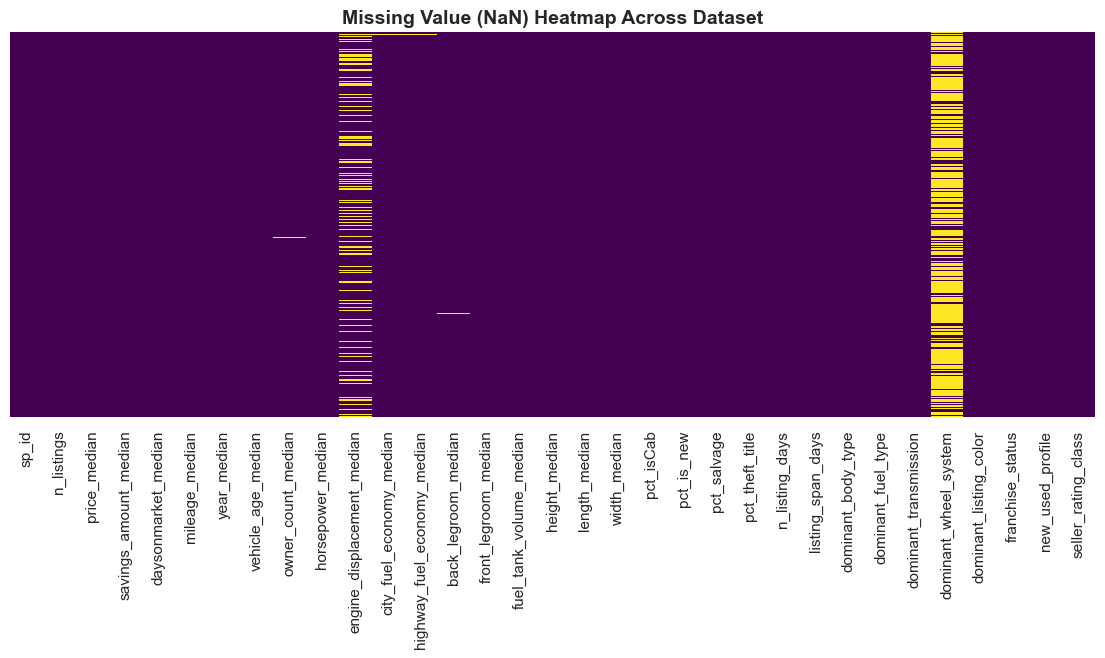

In [7]:
# Summary table of explicit NaN and implicit "unknown" values
missing_summary = []
for col in df.columns:
    nan_cnt = df[col].isnull().sum()
    unk_cnt = (df[col] == "unknown").sum() if df[col].dtype == "object" else 0
    total_miss = nan_cnt + unk_cnt
    if total_miss > 0:
        missing_summary.append({
            "Variable": col,
            "NaN Count": nan_cnt,
            "NaN (%)": round(nan_cnt / len(df) * 100, 2),
            "'unknown' Count": unk_cnt,
            "'unknown' (%)": round(unk_cnt / len(df) * 100, 2),
            "Total Missing": total_miss,
            "Total Missing (%)": round(total_miss / len(df) * 100, 2)
        })

missing_df = pd.DataFrame(missing_summary).sort_values(by="Total Missing", ascending=False)
display(missing_df)

# Visualize Missing Value Heatmap
plt.figure(figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value (NaN) Heatmap Across Dataset", fontsize=14, fontweight="bold")
plt.show()


In [8]:
# Apply Tailored Missing Value Handling on a working copy
df_clean = df.copy()

# 1. Drop dominant_wheel_system (76% missing)
df_clean.drop(columns=["dominant_wheel_system"], inplace=True)

# 2. Mathematical imputation for vehicle_age_median (listing year ~ 2020 - year_median)
mask_age = df_clean["vehicle_age_median"].isnull()
df_clean.loc[mask_age, "vehicle_age_median"] = 2020.0 - df_clean.loc[mask_age, "year_median"]

# 3. Group-based median imputation for engine_displacement_median by dominant_body_type
df_clean["engine_displacement_median"] = df_clean.groupby("dominant_body_type")["engine_displacement_median"].transform(
    lambda x: x.fillna(x.median())
)

# 4. Group-based median imputation for remaining numerical features with minor missing values (< 0.3%)
minor_num_missing = [c for c in num_cols if c in df_clean.columns and df_clean[c].isnull().sum() > 0]
for col in minor_num_missing:
    df_clean[col] = df_clean.groupby("dominant_body_type")[col].transform(lambda x: x.fillna(x.median()))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Remaining explicit NaN values after imputation:", df_clean.isnull().sum().sum())


Remaining explicit NaN values after imputation: 0


### 1.3.2. Outlier and Noise Detection
Visualize numerical distributions via Boxplots, inspect extreme values and semantic anomalies (e.g., `back_legroom_median == 0`), and decide which extreme points represent noise vs. valid domain outliers.


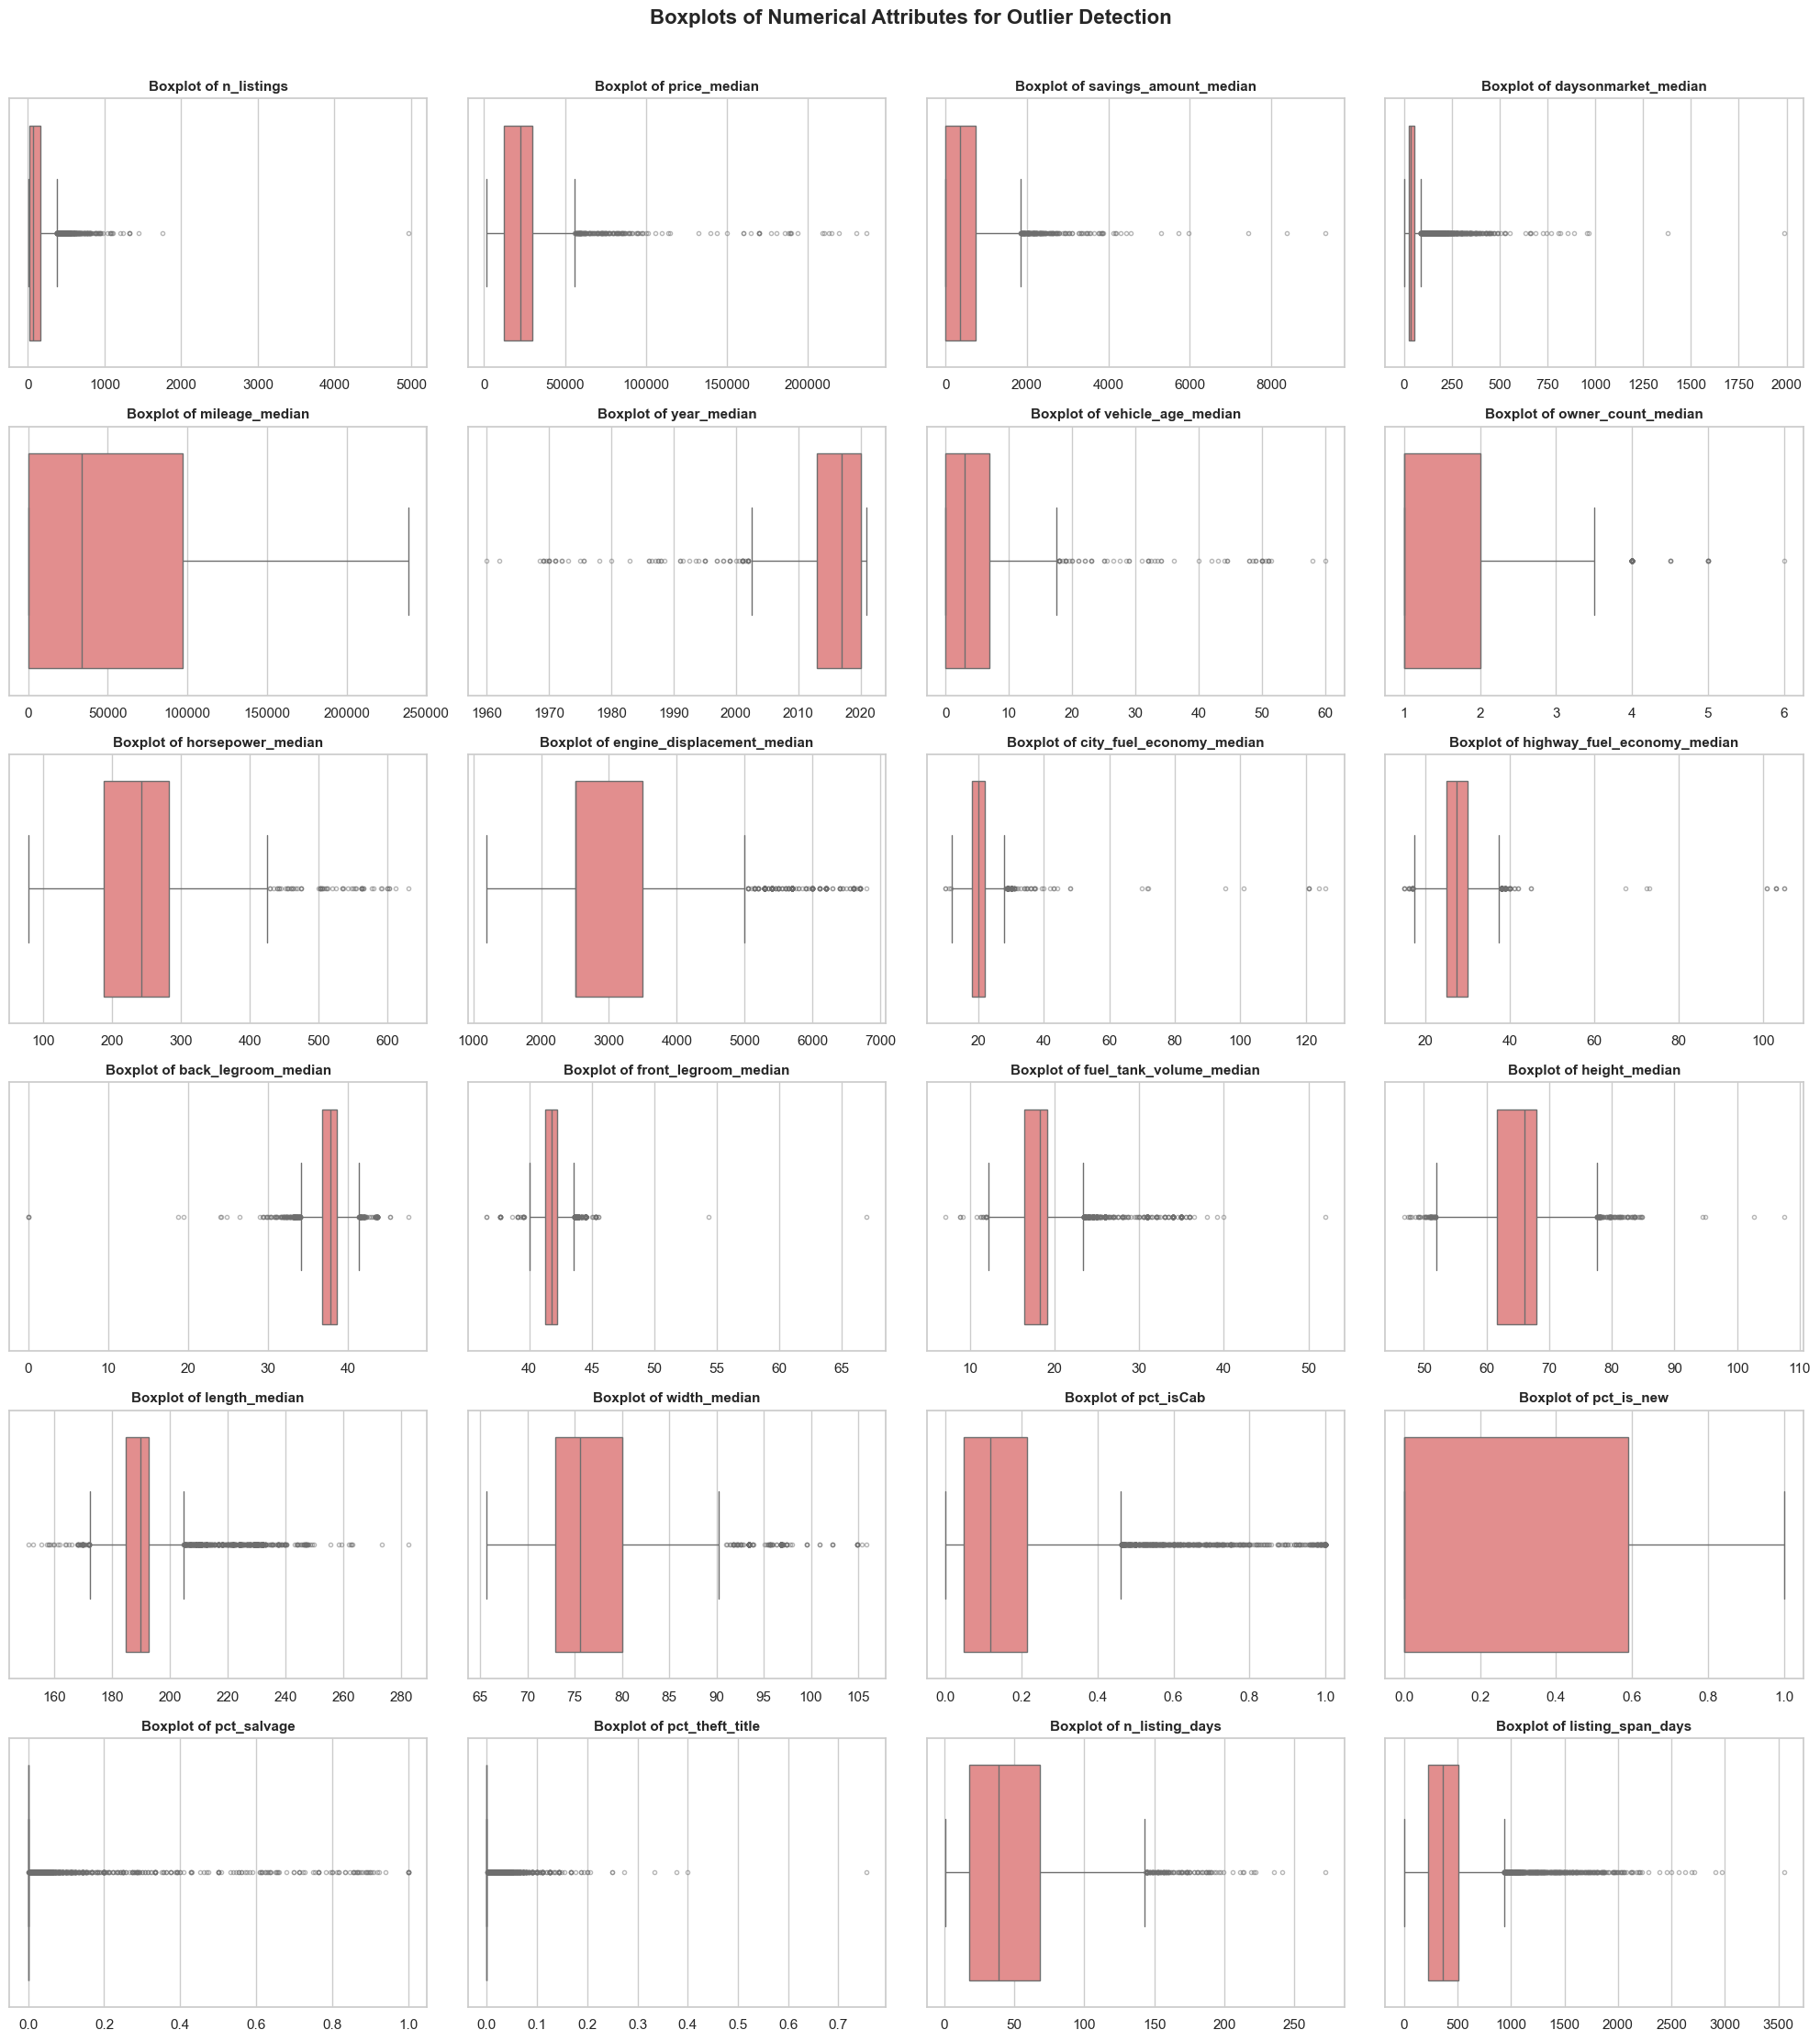

In [9]:
fig, axes = plt.subplots(6, 4, figsize=(20, 22))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    if col in df_clean.columns:
        sns.boxplot(x=df_clean[col], ax=axes[i], color="lightcoral", flierprops={"marker": "o", "markersize": 3, "alpha": 0.5})
        axes[i].set_title(f"Boxplot of {col}", fontsize=11, fontweight="bold")
        axes[i].set_xlabel("")

for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle("Boxplots of Numerical Attributes for Outlier Detection", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


In [10]:
# Inspect potential anomalies and extreme outliers quantitatively (IQR rule & percentiles)
outlier_report = []
for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
    outlier_report.append({
        "Variable": col,
        "Min": df_clean[col].min(),
        "1%": df_clean[col].quantile(0.01),
        "Median": df_clean[col].median(),
        "99%": df_clean[col].quantile(0.99),
        "Max": df_clean[col].max(),
        "IQR Outliers": n_outliers,
        "IQR Outliers (%)": round(n_outliers / len(df_clean) * 100, 2)
    })

display(pd.DataFrame(outlier_report))

# Check rows where back_legroom_median == 0
print("\nRows with back_legroom_median == 0:")
display(df_clean[df_clean["back_legroom_median"] == 0][["sp_id", "dominant_body_type", "back_legroom_median", "front_legroom_median", "length_median"]])


,Variable,Min,1%,Median,99%,Max,IQR Outliers,IQR Outliers (%)
0,n_listings,5.00,5.000,70.000000,572.480000,4959.000000,641,4.63
1,price_median,1699.00,4381.300,22385.000000,59920.570000,236438.000000,171,1.24
2,savings_amount_median,0.00,0.000,358.000000,2086.220000,9333.000000,218,1.57
3,daysonmarket_median,0.00,8.000,36.000000,280.000000,1987.000000,1110,8.02
4,mileage_median,0.00,0.000,33601.000000,174290.000000,238541.000000,0,0.00
5,year_median,1960.00,2004.500,2017.000000,2020.000000,2021.000000,65,0.47
6,vehicle_age_median,0.00,0.000,3.000000,15.000000,60.000000,62,0.45
7,owner_count_median,1.00,1.000,1.000000,3.000000,6.000000,51,0.37
8,horsepower_median,78.00,148.000,243.000000,385.000000,630.000000,62,0.45
9,engine_displacement_median,1200.00,1800.000,2500.000000,5700.000000,6800.000000,328,2.37



Rows with back_legroom_median == 0:


,sp_id,dominant_body_type,back_legroom_median,front_legroom_median,length_median
1699,350763,pickup_truck,0.0,41.3,227.00
1954,353464,pickup_truck,0.0,41.1,226.75
10504,309061,van,0.0,41.3,219.90


---
## 1.4. Variables Transformation
1. **Log-Transformation (`np.log1p`):** Many count, price, and duration attributes (`n_listings`, `price_median`, `savings_amount_median`, `daysonmarket_median`, `mileage_median`, `n_listing_days`) are heavily right-skewed. Applying `log1p` compresses extreme right tails and makes distributions more symmetric.
2. **Feature Scaling (`StandardScaler` / `MinMaxScaler`):** Because features have vastly different scales (e.g., `pct_*` in $[0, 1]$ vs. `price_median` up to $236,438$), scaling is essential for distance-based algorithms (K-Means, DBSCAN, Hierarchical Clustering, KNN).


In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Compare skewness before and after log1p transformation on right-skewed variables
skewed_cols = [col for col in num_cols if df_clean[col].skew() > 1.5 and df_clean[col].min() >= 0]
print("Highly right-skewed columns (skew > 1.5):", skewed_cols)

skew_comparison = pd.DataFrame({
    "Original Skewness": df_clean[skewed_cols].skew().round(2),
    "Log1p Skewness": np.log1p(df_clean[skewed_cols]).skew().round(2)
})
display(skew_comparison)

# Create standardized (Z-score) and normalized (Min-Max) versions for downstream tasks
scaler_z = StandardScaler()
df_zscore = pd.DataFrame(scaler_z.fit_transform(df_clean[num_cols]), columns=num_cols, index=df_clean.index)

scaler_mm = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_mm.fit_transform(df_clean[num_cols]), columns=num_cols, index=df_clean.index)

print("Z-Score Standardized Data (mean ~ 0, std ~ 1):")
display(df_zscore.describe().loc[["mean", "std", "min", "max"]].round(2))


Highly right-skewed columns (skew > 1.5): ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median', 'vehicle_age_median', 'engine_displacement_median', 'city_fuel_economy_median', 'highway_fuel_economy_median', 'front_legroom_median', 'fuel_tank_volume_median', 'length_median', 'pct_isCab', 'pct_salvage', 'pct_theft_title', 'listing_span_days']


,Original Skewness,Log1p Skewness
n_listings,5.25,-0.13
price_median,3.45,-0.45
savings_amount_median,2.40,-0.40
daysonmarket_median,8.75,0.47
vehicle_age_median,2.32,0.00
engine_displacement_median,1.55,0.64
city_fuel_economy_median,8.10,0.96
highway_fuel_economy_median,3.87,0.48
front_legroom_median,3.49,2.15
fuel_tank_volume_median,1.83,0.90


Z-Score Standardized Data (mean ~ 0, std ~ 1):


,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days
mean,-0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.83,-1.49,-0.86,-0.88,-0.99,-11.85,-0.88,-0.69,-2.86,-2.24,-2.69,-3.24,-24.08,-6.88,-3.83,-3.69,-3.91,-2.28,-0.99,-0.84,-0.15,-0.24,-1.34,-1.44
max,35.32,14.85,17.11,34.57,3.61,1.07,12.07,7.33,6.83,5.34,26.62,19.40,6.25,32.68,11.50,8.55,8.90,5.82,5.32,2.31,15.26,46.32,6.69,11.15


---
## 1.5. Pairwise Correlations and Variable Elimination
### 1.5.1. Pairwise Scatter Plot Matrix
Visualize pairwise relationships among representative numerical attributes to observe linear and non-linear trends.


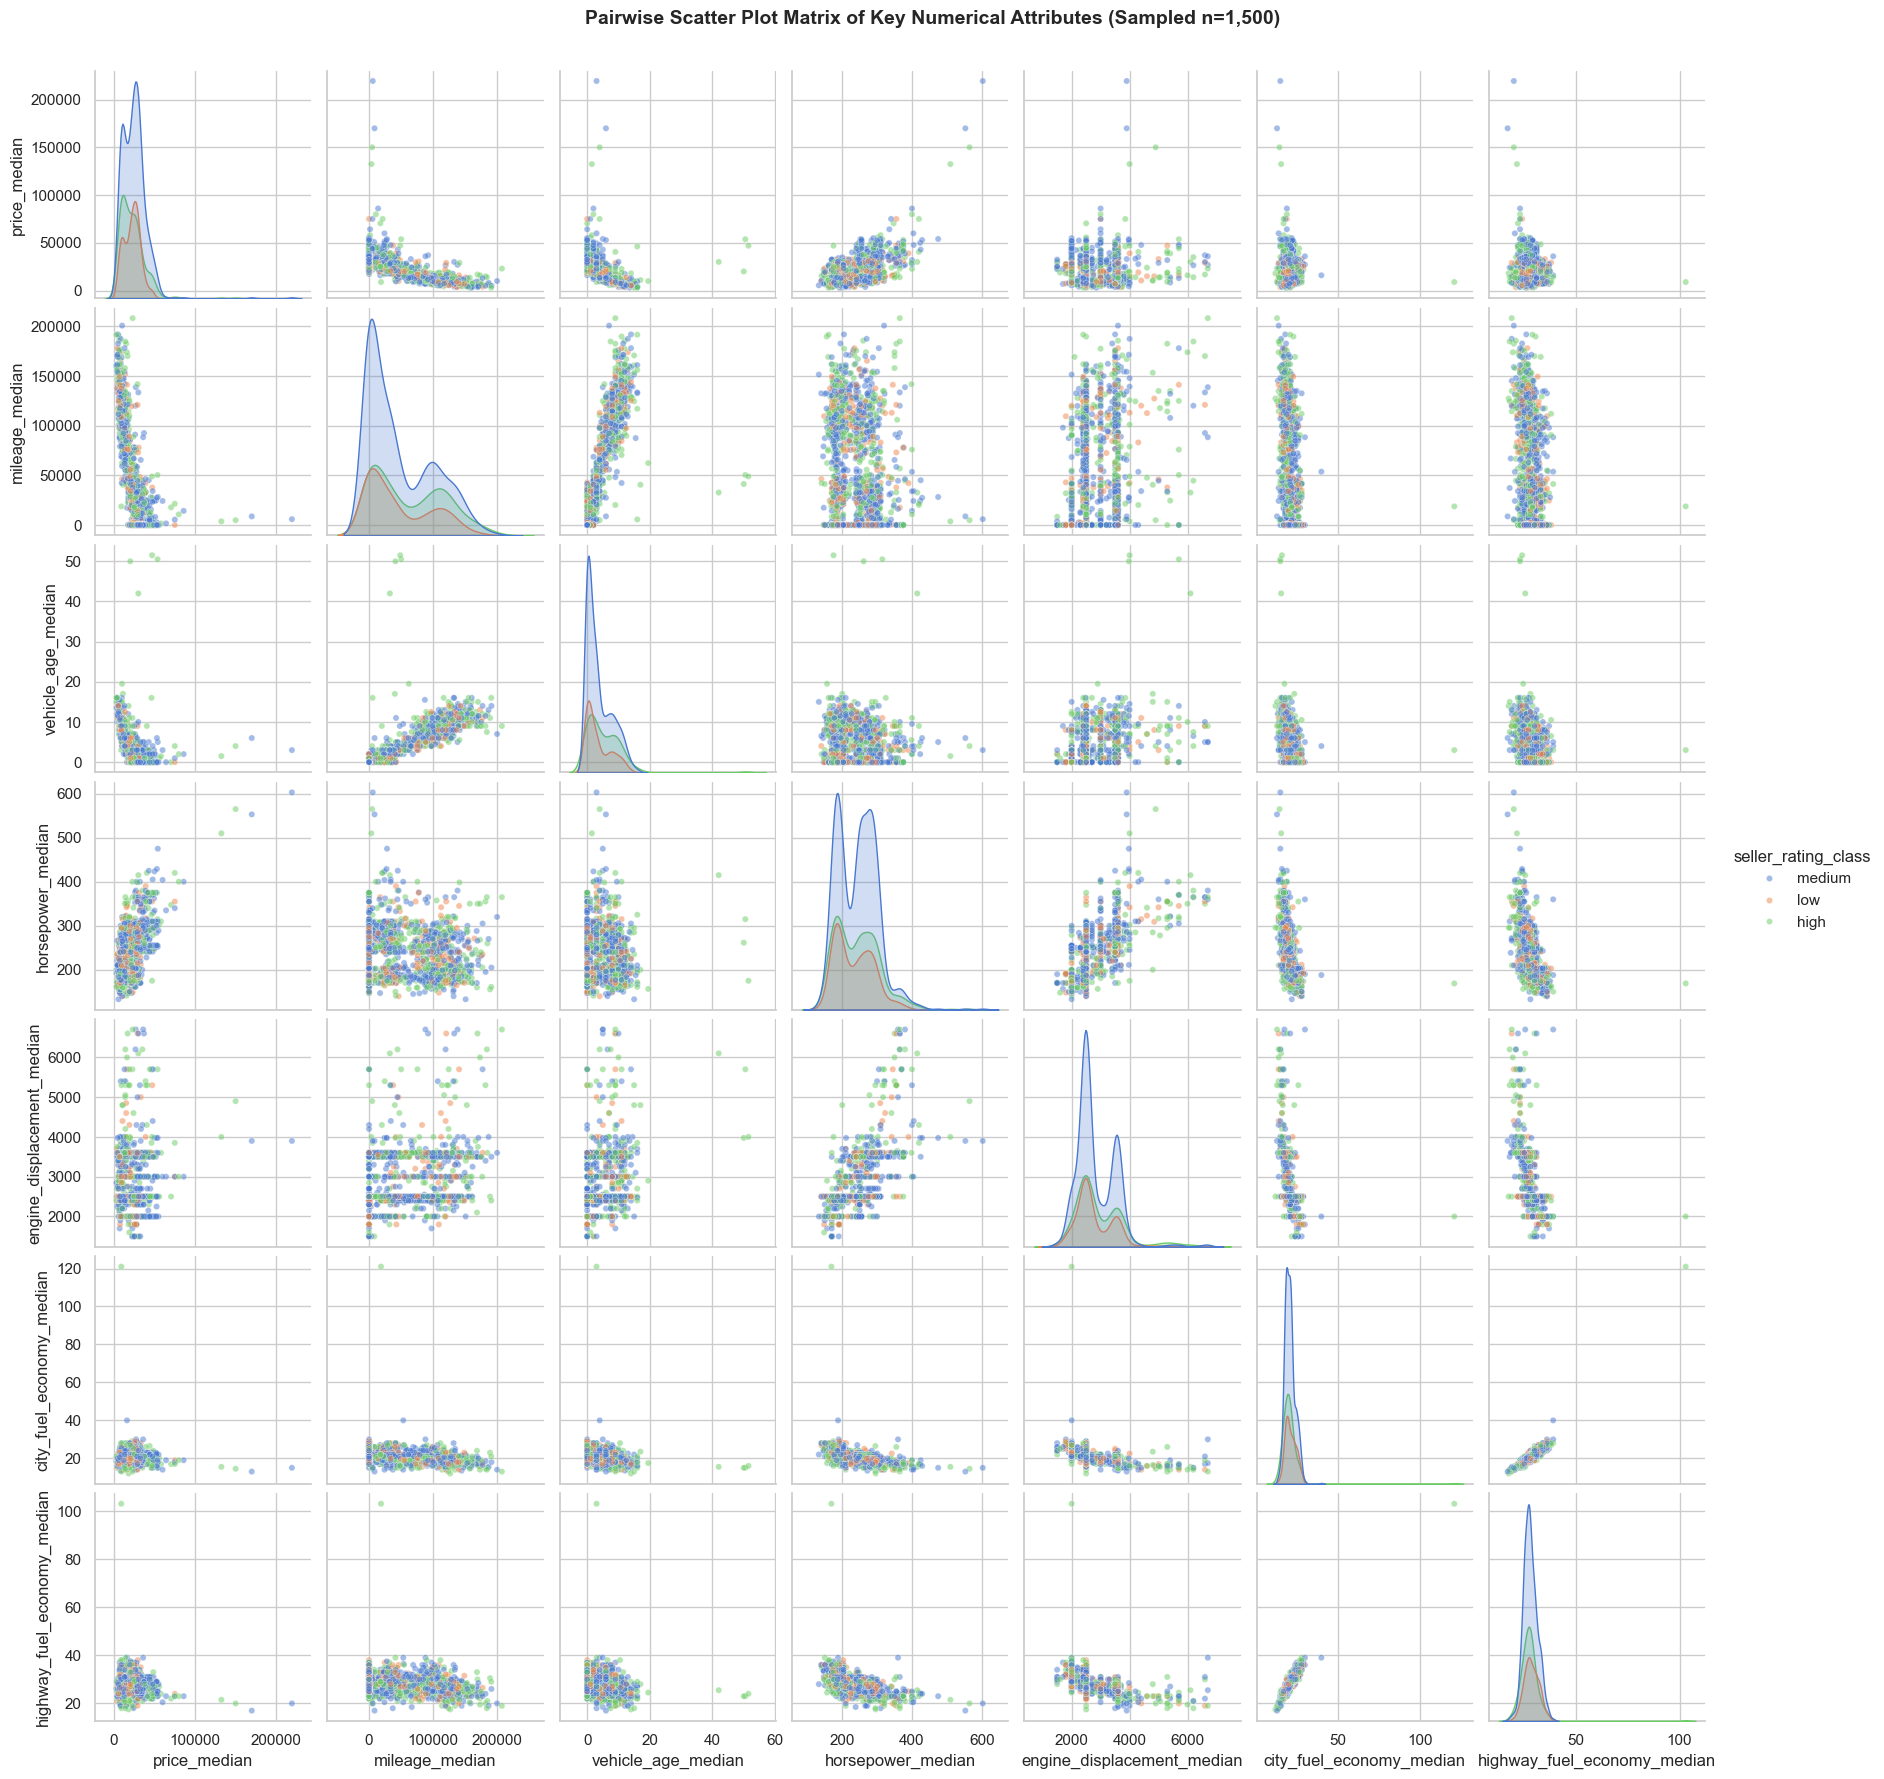

In [12]:
sample_pair_cols = [
    "price_median", "mileage_median", "vehicle_age_median",
    "horsepower_median", "engine_displacement_median",
    "city_fuel_economy_median", "highway_fuel_economy_median"
]

sns.pairplot(
    df_clean[sample_pair_cols + ["seller_rating_class"]].sample(n=1500, random_state=42),
    hue="seller_rating_class",
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 20}
)
plt.suptitle("Pairwise Scatter Plot Matrix of Key Numerical Attributes (Sampled n=1,500)", y=1.02, fontsize=14, fontweight="bold")
plt.show()


### 1.5.2. Spearman Correlation Matrix Heatmap & Redundant Feature Elimination
We compute the **Spearman rank correlation matrix** (more robust to outliers and non-linear monotonic relationships than Pearson) and identify highly correlated feature pairs ($|r_s| > 0.80$) to eliminate redundant attributes.


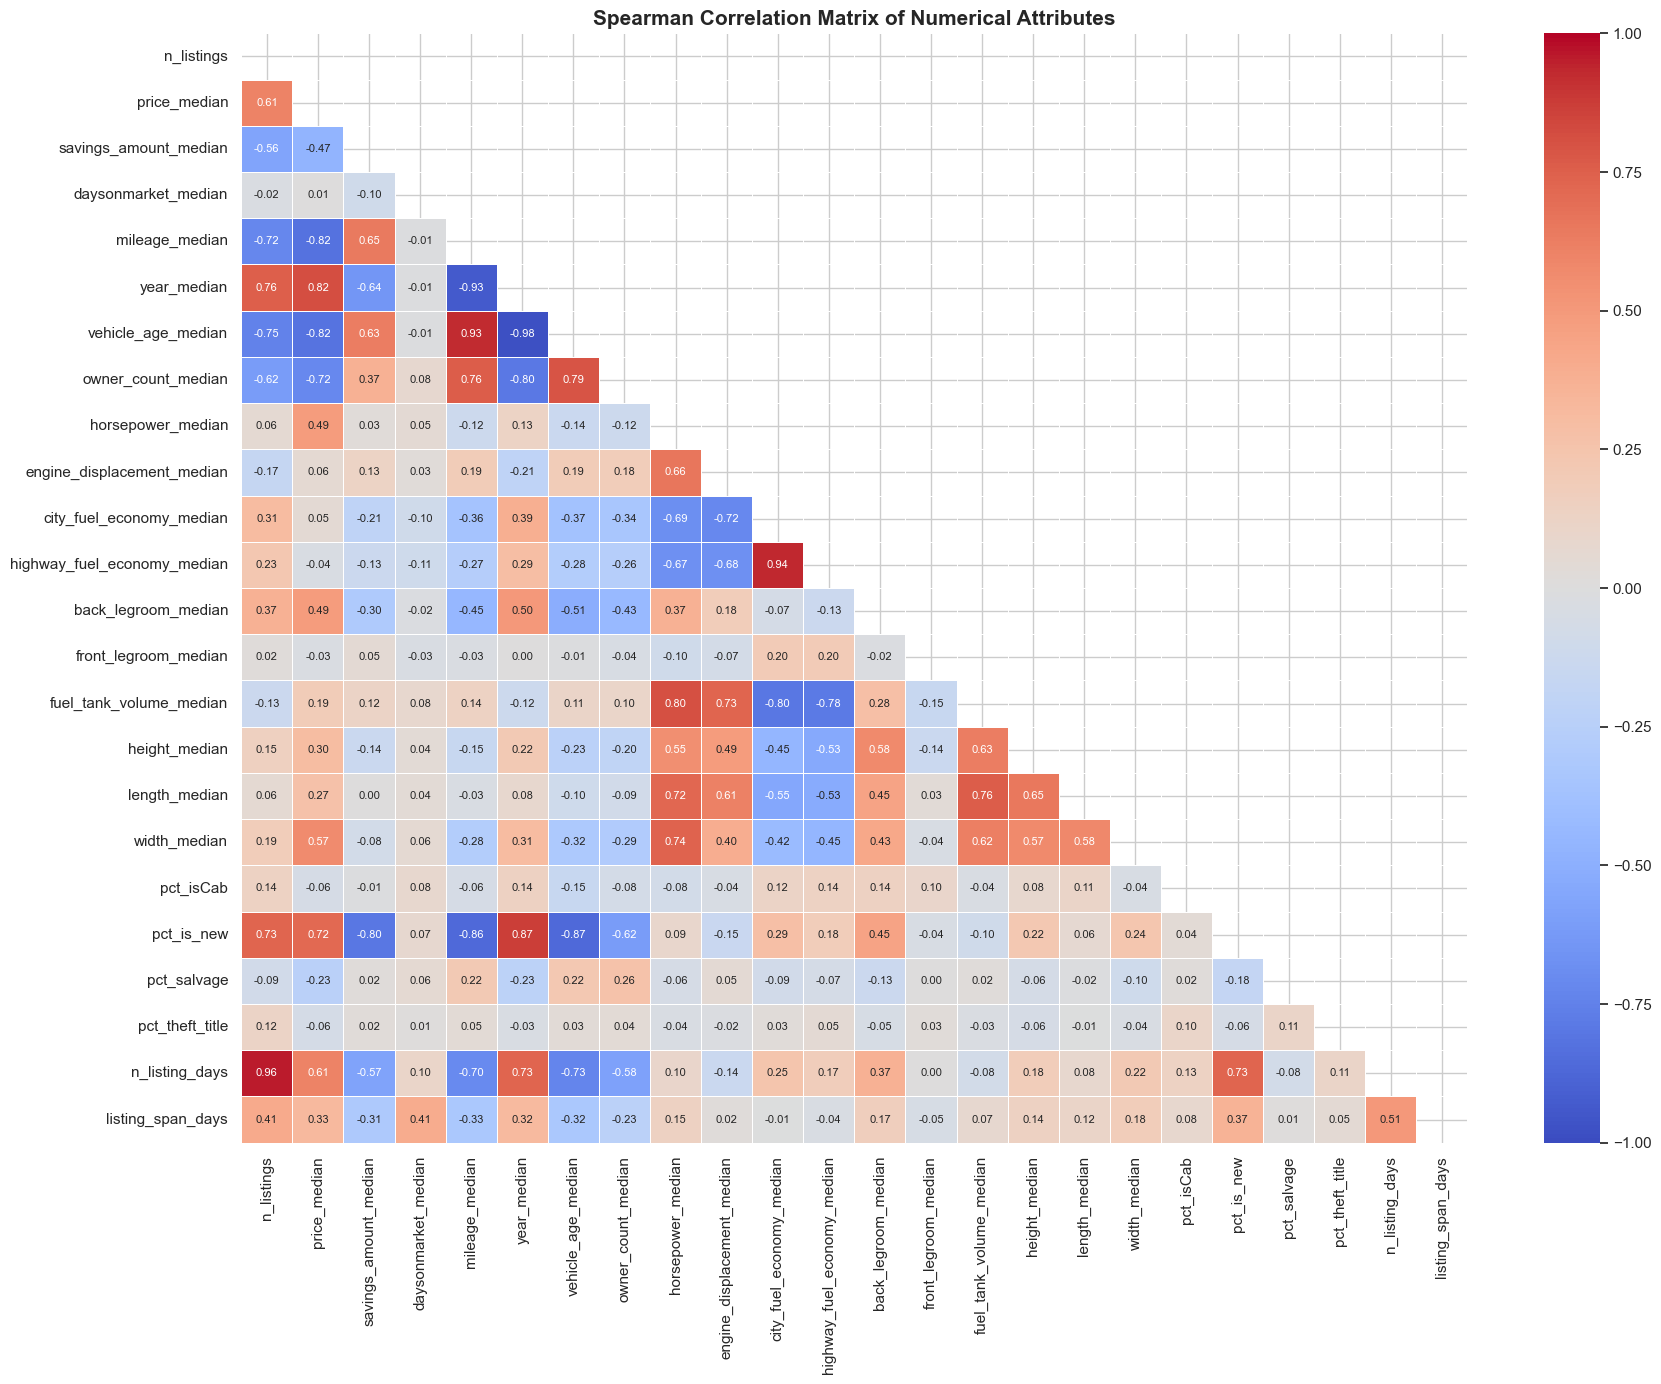

=== HIGHLY CORRELATED PAIRS (|r| >= 0.70) ===


,Feature 1,Feature 2,Spearman r
16,year_median,vehicle_age_median,-0.9837
4,n_listings,n_listing_days,0.9559
28,city_fuel_economy_median,highway_fuel_economy_median,0.9356
11,mileage_median,year_median,-0.9316
12,mileage_median,vehicle_age_median,0.9268
18,year_median,pct_is_new,0.8727
21,vehicle_age_median,pct_is_new,-0.8671
14,mileage_median,pct_is_new,-0.8614
5,price_median,mileage_median,-0.8226
6,price_median,year_median,0.8195


In [13]:
corr_spearman = df_clean[num_cols].corr(method="spearman")

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title("Spearman Correlation Matrix of Numerical Attributes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# List all pairs with |Spearman correlation| >= 0.70
high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        c1, c2 = num_cols[i], num_cols[j]
        val = corr_spearman.loc[c1, c2]
        if abs(val) >= 0.70:
            high_corr_pairs.append({"Feature 1": c1, "Feature 2": c2, "Spearman r": round(val, 4)})

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values(by="Spearman r", key=abs, ascending=False)
print("=== HIGHLY CORRELATED PAIRS (|r| >= 0.70) ===")
display(high_corr_df)


In [14]:
# Eliminate redundant features and identifier before downstream modeling
cols_to_drop = [
    "sp_id",                        # Unique identifier (no predictive/clustering value)
    "year_median",                  # Perfectly redundant with vehicle_age_median (r ~ -0.99)
    "highway_fuel_economy_median",  # Highly collinear with city_fuel_economy_median
]

df_final = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])
print(f"Final Prepared Dataset Shape: {df_final.shape[0]:,} rows x {df_final.shape[1]} columns")
print("Remaining columns:", df_final.columns.tolist())


Final Prepared Dataset Shape: 13,843 rows x 29 columns
Remaining columns: ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median', 'mileage_median', 'vehicle_age_median', 'owner_count_median', 'horsepower_median', 'engine_displacement_median', 'city_fuel_economy_median', 'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median', 'height_median', 'length_median', 'width_median', 'pct_isCab', 'pct_is_new', 'pct_salvage', 'pct_theft_title', 'n_listing_days', 'listing_span_days', 'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission', 'dominant_listing_color', 'franchise_status', 'new_used_profile', 'seller_rating_class']
